In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pathlib import Path
import mne
import csv
import json
import sys

print(__doc__)

PROJECT_ROOT = Path.cwd().resolve()

# Nach oben gehen, bis das Datenverzeichnis gefunden wird
while not (PROJECT_ROOT / "data" / "raw" / "ds005363-download").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Projektverzeichnis nicht gefunden.")

    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "ds005363-download"

BUNDLE_DIR = PROJECT_ROOT / "notebooks" / "BunDLe-Net"
if str(BUNDLE_DIR) not in sys.path:
    sys.path.insert(0, str(BUNDLE_DIR))

print("Arbeitsverzeichnis:", Path.cwd())
print("Datenverzeichnis:", DATA_ROOT)

def first_matching(directory: Path, pattern: str) -> Path:
    matches = sorted(directory.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"Keine Datei mit Muster {pattern!r} in {directory}")
    return matches[0]

def read_tsv(path: Path) -> list[dict[str, str]]:
    """Liest eine TSV-Datei robust gegen ein UTF-8-BOM ein."""

    with path.open("r", encoding="utf-8-sig", newline="") as file:
        return list(csv.DictReader(file, delimiter="\t"))
    
def subject_directory(data_root: Path, subject: str) -> Path:
    subject_label = subject if subject.startswith("sub-") else f"sub-{subject}"
    directory = data_root / subject_label / "ses-01" / "eeg"
    if not directory.is_dir():
        raise FileNotFoundError(f"EEG-Verzeichnis nicht gefunden: {directory}")
    return directory

subjects_dir = subject_directory(DATA_ROOT, "101")

def read_data(subject: str, duration: float, data_root: Path, output_root: Path): 
    eeg_dir = subject_directory(data_root, subject)

    vhdr_path = first_matching(eeg_dir, "*_eeg.vhdr")
    json_path = first_matching(eeg_dir, "*_eeg.json")
    channels_path = first_matching(eeg_dir, "*_channels.tsv")
    events_path = first_matching(eeg_dir, "*_events.tsv")

    with json_path.open("r", encoding="utf-8") as file:
        metadata = json.load(file)
    channels = read_tsv(channels_path)
    events = read_tsv(events_path)

    print(f"Lese BrainVision-Aufnahme ein: {vhdr_path}")
    raw = mne.io.read_raw_brainvision(vhdr_path, preload=True, verbose="ERROR")
    eeg_picks = mne.pick_types(raw.info, eeg=True, exclude=[])
    if len(eeg_picks) == 0:
        raise RuntimeError("Die Aufnahme enthält keine als EEG markierten Kanäle.")

    return raw, channels, events

Automatically created module for IPython interactive environment
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download


In [ ]:
try:
    raw, channels, events = read_data(
        subject="101",
        duration=60.0,
        data_root=DATA_ROOT,
        output_root=PROJECT_ROOT / "results",
    )
    raw.set_montage("standard-1020")

except FileNotFoundError as exc:
    raise SystemExit(f"Datei nicht verfügbar: {exc}") from exc
except RuntimeError as exc:
    raise SystemExit(f"Analyse konnte nicht durchgeführt werden: {exc}") from exc


Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr


In [3]:
raw.load_data()
raw.filter(l_freq=0.5, h_freq=None)

events_arr, event_dict = mne.events_from_annotations(raw)

categories = {"face": range(1, 17), "animal": range(17, 33),
              "place": range(33, 49), "object": range(49, 65)}

event_id = {f"{name}/S{n}": event_dict[f"Stimulus/S{n:>3}"]
            for name, nums in categories.items() for n in nums}

epochs = mne.Epochs(raw, events_arr, event_id=event_id,
                    tmin=-0.3, tmax=0.7, baseline=(None, 0),
                    preload=True, event_repeated="drop")


Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 6601 samples (6.601 s)

Used Annotations descriptions: [np.str_('Comment/actiCAP Data On'), np.str_('Stimulus/S  1'), np.str_('Stimulus/S  2'), np.str_('Stimulus/S  3'), np.str_('Stimulus/S  4'), np.str_('Stimulus/S  5'), np.str_('Stimulus/S  6'), np.str_('Stimulus/S  7'), np.str_('Stimulus/S  8'), np.str_('Stimulus/S  9'), np.str_('Stimulus/S 10'), np.str_('Stimulus/S 11'), np.str_('Stimulus/S 12'), np.str_('Stimulus/S 13'), np.str_('Stimulus/S 14'), np.str_('Stimulus/S 15'), np.str_('Stimulus/S 16'), np.str_('Stimulus/S 17'), np.str_('Stimulus/S 18'), np.str_('Stim

Estimating rejection dictionary for eeg
0 bad epochs dropped


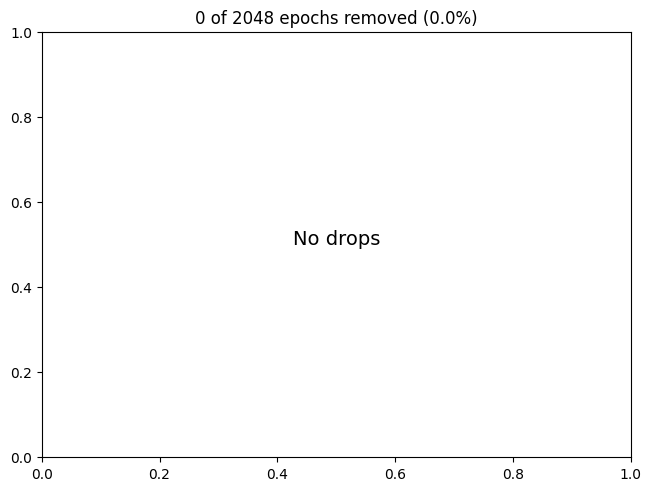

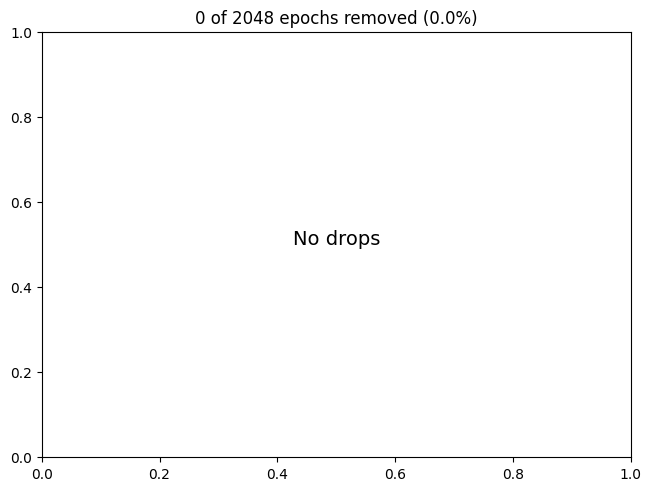

In [4]:
import autoreject

epochs.resample(250)                    

rng = np.random.default_rng(11)
fit_idx = rng.choice(len(epochs), 200, replace=False)   

"""ar = autoreject.AutoReject(n_interpolate=[1, 4], random_state=11,
                           n_jobs=-1, verbose=True)     
ar.fit(epochs[fit_idx])
epochs_ar, reject_log = ar.transform(epochs, return_log=True)"""

reject = autoreject.get_rejection_threshold(epochs)   # z. B. {'eeg': 1.2e-4}
epochs_clean = epochs.copy().drop_bad(reject=reject)
epochs_clean
epochs_clean.plot_drop_log()

In [5]:
n_train = int(0.8 * len(epochs_clean))
idx = rng.permutation(len(epochs_clean))

epochs_train = epochs_clean[idx[:n_train]]
epochs_test = epochs_clean[idx[n_train:]]

X_train = epochs_train.get_data()
X_test = epochs_test.get_data()

scaler = mne.decoding.Scaler(scalings="mean")
X_train = scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

print(X_train.shape, X_test.shape) 

(1638, 64, 250) (410, 64, 250)


In [6]:
def make_B(ep):
    codes = ep.events[:, 2]
    cat = (codes - 1) // 16 + 1            # 1=face, 2=animal, 3=place, 4=object
    B = np.zeros((len(ep), len(ep.times)), dtype=int)
    B[:, ep.times >= 0] = cat[:, None]
    return B

B_train = make_B(epochs_train)    # (1638, 250)

B_test  = make_B(epochs_test)     # (410, 250)
print(B_test.shape)
print(B_train.shape)
print(epochs.events.shape)

(410, 250)
(1638, 250)
(2048, 3)


In [7]:
epochs_face_obj = epochs_clean[["face", "object"]]
X_train_face_obj = epochs_face_obj.get_data()
X_train_face_obj = scaler.fit_transform(X_train_face_obj)
print(epochs_face_obj)

NUMBER_OF_IMAGES_PER_CATEGORY = 16
LABEL_BEFORE_IMAGE_ONSET = 0

def create_labels_for_epochs(epochs):
    """
    Gibt eine Matrix mit der Form (Anzahl Epochs, Anzahl Zeitpunkte) zurück.
    Vor dem Bildbeginn steht 0, ab dem Bildbeginn die Kategorie:
    1 = Gesicht, 2 = Tier, 3 = Ort, 4 = Objekt.
    """
    image_numbers = epochs.events[:, 2]

    category_per_epoch = (image_numbers - 1) // NUMBER_OF_IMAGES_PER_CATEGORY + 1

    number_of_epochs = len(epochs)
    number_of_time_points = len(epochs.times)
    labels = np.full(
        (number_of_epochs, number_of_time_points),
        LABEL_BEFORE_IMAGE_ONSET,
        dtype=int,
    )

    time_points_after_image_onset = epochs.times >= 0
    for epoch_number in range(number_of_epochs):
        labels[epoch_number, time_points_after_image_onset] = category_per_epoch[epoch_number]

    return labels, category_per_epoch


<Epochs | 1024 events (all good), -0.3 – 0.696 s (baseline -0.3 – 0 s), ~125.1 MiB, data loaded,
 'face/S1': 32
 'face/S2': 32
 'face/S3': 32
 'face/S4': 32
 'face/S5': 32
 'face/S6': 32
 'face/S7': 32
 'face/S8': 32
 'face/S9': 32
 'face/S10': 32
 and 22 more events ...>


Spatio-temporal: 85.9%
Computing rank from data with rank=None
    Using tolerance 36 (2.2e-16 eps * 64 dim * 2.6e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=4 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 35 (2.2e-16 eps * 64 dim * 2.5e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=4 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 35 (2.2e-16 eps * 64 dim * 2.5e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance u

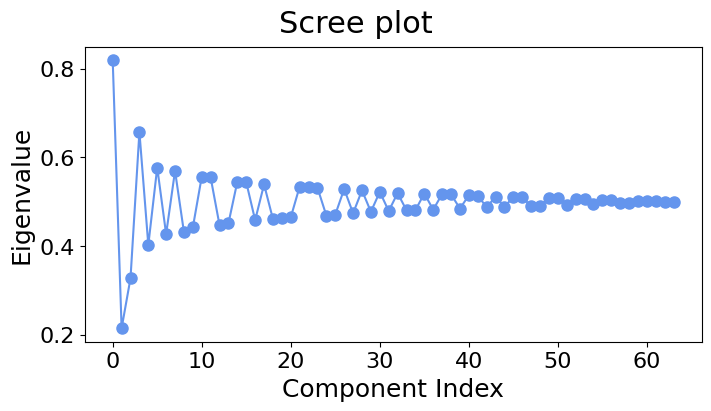

RuntimeError: No digitization points found.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from mne.decoding import (
    CSP,
    GeneralizingEstimator,
    LinearModel,
    Scaler,
    SlidingEstimator,
    Vectorizer,
    cross_val_multiscore,
    get_coef,
    get_spatial_filter_from_estimator,
)

labels_train, category_per_epoch= create_labels_for_epochs(epochs_face_obj) 

# Uses all MEG sensors and time points as separate classification
# features, so the resulting filters used are spatio-temporal
clf = make_pipeline(
    Scaler(epochs.info),
    Vectorizer(),
    # liblinear is faster than lbfgs
    LogisticRegression(solver="liblinear", random_state=31),
)

scores = cross_val_multiscore(clf, X_train_face_obj, category_per_epoch, cv=5, n_jobs=None)

# Mean scores across cross-validation splits
score = np.mean(scores, axis=0)
print(f"Spatio-temporal: {100 * score:0.1f}%")

csp = CSP(n_components=3, norm_trace=False)
clf_csp = make_pipeline(
    csp, LinearModel(LogisticRegression(solver="liblinear", random_state=37))
)
scores = cross_val_multiscore(clf_csp, X_train_face_obj, category_per_epoch, cv=5, n_jobs=None)
print(f"CSP: {100 * scores.mean():0.1f}%")

csp.fit(X_train_face_obj, category_per_epoch)
spf = get_spatial_filter_from_estimator(csp, info=epochs.info)
spf.plot_scree()
spf.plot_patterns(components=[0, 1, 2])
spf.plot_filters(components=[0, 1, 2], scalings=1e-9)

clf = make_pipeline(
    StandardScaler(), LogisticRegression(solver="liblinear", random_state=41)
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="roc_auc", verbose=True)
# here we use cv=3 just for speed
scores = cross_val_multiscore(time_decod, X_train_face_obj, category_per_epoch, cv=3, n_jobs=None)

# Mean scores across cross-validation splits
scores = np.mean(scores, axis=0)

# Plot
fig, ax = plt.subplots()
ax.plot(epochs.times, scores, label="score")
ax.axhline(0.5, color="k", linestyle="--", label="chance")
ax.set_xlabel("Times")
ax.set_ylabel("AUC")  # Area Under the Curve
ax.legend()
ax.axvline(0.0, color="k", linestyle="-")
ax.set_title("Sensor space decoding")

clf = make_pipeline(
    StandardScaler(),
    LinearModel(LogisticRegression(solver="liblinear", random_state=43)),
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="roc_auc", verbose=True)
time_decod.fit(X_train_face_obj, category_per_epoch)

coef = get_coef(time_decod, "patterns_", inverse_transform=True)
evoked_time_gen = mne.EvokedArray(coef, epochs.info, tmin=epochs.times[0])
joint_kwargs = dict(ts_args=dict(time_unit="s"), topomap_args=dict(time_unit="s"))
evoked_time_gen.plot_joint(
    times=np.arange(0.0, 0.500, 0.100), title="patterns", **joint_kwargs
)
